# 03 ? Statistical Analysis

## ChronoTunnel | Urban Mobility Intelligence Platform

**Objective:** Evaluate ridership distributions, compare borough and transit-mode patterns, and statistically assess sampled Wednesday?Saturday ridership differences.

This notebook uses the production statistical functions implemented in `src/chronotunnel/analysis/statistical.py`.

### Research questions
1. How is monthly station-level ridership distributed?
2. How do ridership distributions vary across boroughs and transit modes?
3. Is sampled Wednesday ridership different from Saturday ridership?
4. What is the magnitude and uncertainty of the paired difference?

### Methodological principles
- Descriptive statistics summarize the observed data.
- Mann?Whitney U provides an independent-sample comparison.
- Wilcoxon signed-rank provides a paired comparison across matched months.
- Statistical significance is interpreted alongside effect size and confidence intervals.
- Statistical association does not establish causation.


## 1. Environment and reproducibility

Load the project dependencies and identify the project root before importing production modules.


In [1]:
import sys
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "pyproject.toml").exists()
        and (path / "src" / "chronotunnel").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the ChronoTunnel project root.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("DuckDB:", duckdb.__version__)

Project root: D:\ChronoTunnel
Python: 3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]
Pandas: 3.1.1
NumPy: 2.5.4
DuckDB: 2.0.0


## 2. Load datasets and establish analytical connection

The monthly dataset supports distributional and group-level analysis. The hourly dataset contains 120 deliberately selected dates: one Wednesday and one Saturday per month.

The two datasets have different coverage and must not be treated as equivalent samples.


In [2]:
DATA_DIR = PROJECT_ROOT / "data" / "processed"

HOURLY_FILE = DATA_DIR / "hourly_ridership_sample_station_level_2020_2024.csv"
MONTHLY_FILE = DATA_DIR / "monthly_ridership_station_level_2020_2024.csv"

for file_path in [HOURLY_FILE, MONTHLY_FILE]:
    if not file_path.exists():
        raise FileNotFoundError(f"Required dataset not found: {file_path}")

hourly = pd.read_csv(HOURLY_FILE)
monthly = pd.read_csv(MONTHLY_FILE)

hourly["transit_timestamp"] = pd.to_datetime(
    hourly["transit_timestamp"], errors="raise"
)
monthly["month"] = pd.to_datetime(monthly["month"], errors="raise")

connection = duckdb.connect(database=":memory:")

connection.register("hourly_df", hourly)
connection.register("monthly_df", monthly)

connection.execute("CREATE VIEW hourly AS SELECT * FROM hourly_df")
connection.execute("CREATE VIEW monthly AS SELECT * FROM monthly_df")

print("Hourly shape:", hourly.shape)
print("Monthly shape:", monthly.shape)
print(
    "Hourly date range:",
    hourly["transit_timestamp"].min(),
    "to",
    hourly["transit_timestamp"].max(),
)
print("Monthly date range:", monthly["month"].min(), "to", monthly["month"].max())
print("Hourly sampled dates:", hourly["transit_timestamp"].dt.date.nunique())
print("Monthly observations:", len(monthly))

Hourly shape: (1172916, 10)
Monthly shape: (25679, 10)
Hourly date range: 2020-01-11 00:00:00 to 2024-12-14 23:00:00
Monthly date range: 2020-01-01 00:00:00 to 2024-12-01 00:00:00


Hourly sampled dates: 120
Monthly observations: 25679


## 3. Import production statistical functions

The following functions are reused directly from ChronoTunnel production code. No separate implementation of the core statistical calculations is introduced here.


In [ ]:
from src.chronotunnel.analysis.statistical import (
    compare_paired_weekday_weekend_ridership,
    compare_weekday_weekend_ridership,
    get_borough_statistics,
    get_ridership_distribution,
    get_transit_mode_statistics,
)

print("Production statistical functions imported successfully.")

Production statistical functions imported successfully.


## 4. Overall ridership distribution

Analyze the distribution of monthly station-level ridership observations.

The mean and median help characterize central tendency. Quartiles and standard deviation describe dispersion, while skewness indicates distribution asymmetry.


In [4]:
distribution = get_ridership_distribution(connection)
display(distribution)

distribution_metrics = distribution.iloc[0]

print(f"Observations: {int(distribution_metrics['observations']):,}")
print(f"Mean: {distribution_metrics['mean_ridership']:,.2f}")
print(f"Median: {distribution_metrics['median_ridership']:,.2f}")
print(f"Skewness: {distribution_metrics['skewness']:.4f}")

,observations,mean_ridership,median_ridership,standard_deviation,minimum_ridership,first_quartile,third_quartile,maximum_ridership,skewness
0,25679,187026.94,104090.0,281295.35,1,56351.0,209056.0,5141295,5.7829


Observations: 25,679
Mean: 187,026.94
Median: 104,090.00
Skewness: 5.7829


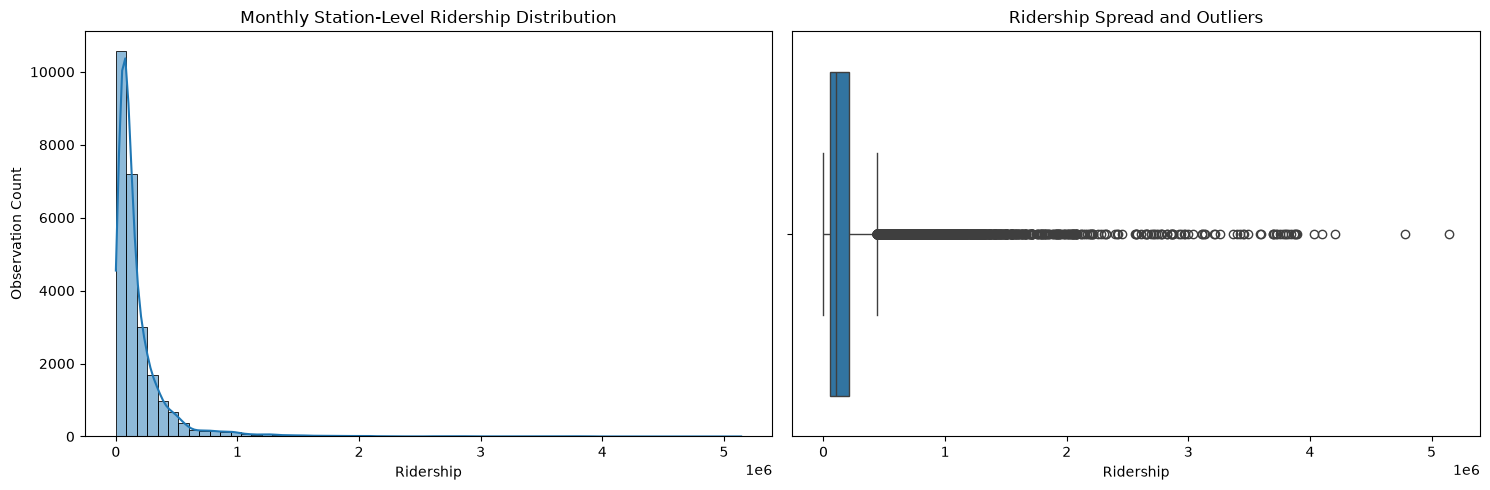

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    monthly["ridership"],
    bins=60,
    kde=True,
    ax=axes[0],
)
axes[0].set_title("Monthly Station-Level Ridership Distribution")
axes[0].set_xlabel("Ridership")
axes[0].set_ylabel("Observation Count")

sns.boxplot(
    x=monthly["ridership"],
    ax=axes[1],
)
axes[1].set_title("Ridership Spread and Outliers")
axes[1].set_xlabel("Ridership")

plt.tight_layout()
plt.show()

### Interpretation

Ridership observations are expected to exhibit substantial variation because station complexes differ in size, location and demand.

A right-skewed distribution indicates that a relatively small number of high-volume station-month observations influence the mean. The median is therefore an important complementary measure.

These are monthly station-level observations, not independent passenger-level records.


## 5. Borough-level statistical comparison

Compare average and median monthly station-level ridership across boroughs. Observation counts and unique station counts provide important context for interpretation.


,borough,observations,unique_stations,average_ridership,median_ridership,standard_deviation,minimum_ridership,maximum_ridership
0,Manhattan,7379,123,349193.20,217473.0,442809.72,1,5141295
1,Queens,4740,79,155018.14,87681.0,189857.63,10,1474202
2,Brooklyn,9359,156,117338.68,86453.0,110853.70,3,1188320
3,Bronx,4080,68,94157.54,81529.0,65626.56,6381,632224
4,Staten Island,121,2,73115.00,14914.0,72968.20,2,291539


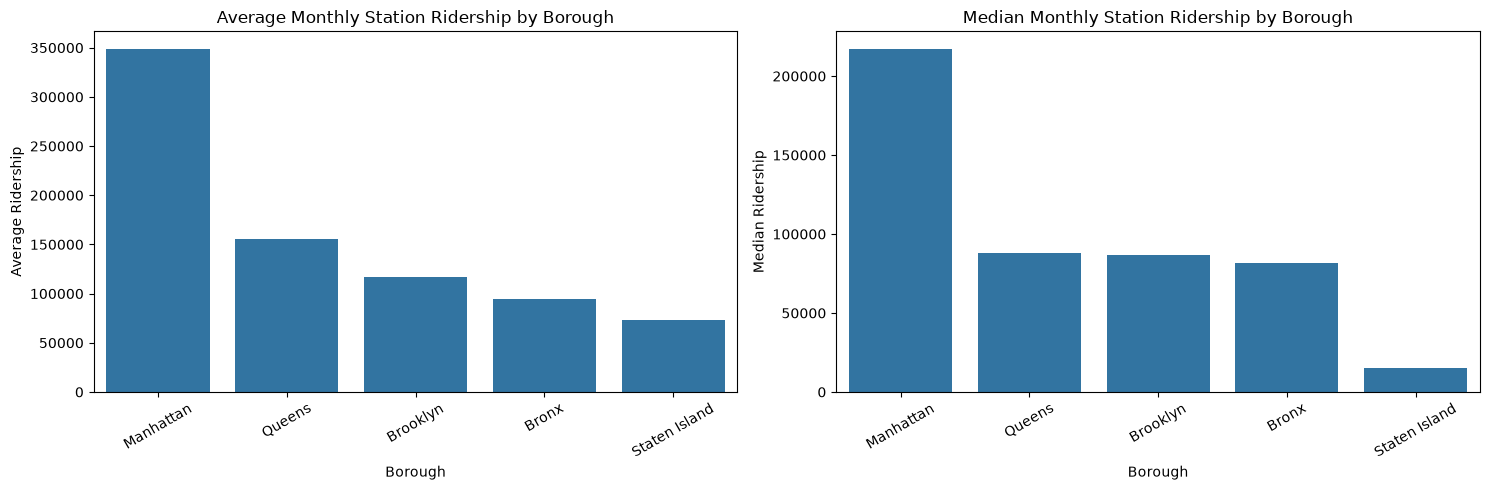

In [6]:
borough_statistics = get_borough_statistics(connection)
display(borough_statistics)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=borough_statistics,
    x="borough",
    y="average_ridership",
    ax=axes[0],
)
axes[0].set_title("Average Monthly Station Ridership by Borough")
axes[0].set_xlabel("Borough")
axes[0].set_ylabel("Average Ridership")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=borough_statistics,
    x="borough",
    y="median_ridership",
    ax=axes[1],
)
axes[1].set_title("Median Monthly Station Ridership by Borough")
axes[1].set_xlabel("Borough")
axes[1].set_ylabel("Median Ridership")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Interpretation

Borough-level differences reflect the combined effects of station demand, network structure and the number of stations represented.

The descriptive statistics do not establish that borough location itself causes higher or lower ridership. Station-level observations within the same borough may also share contextual characteristics.


## 6. Transit-mode statistical comparison

Compare monthly ridership distributions by transit mode using the production statistical function.


,transit_mode,observations,unique_stations,average_ridership,median_ridership,standard_deviation,minimum_ridership,maximum_ridership
0,subway,25439,425,188024.02,104397.0,282371.88,1,5141295
1,tram,120,2,88957.15,84847.0,41119.09,11688,172946
2,staten_island_railway,120,2,73724.27,17249.5,72964.42,3254,291539


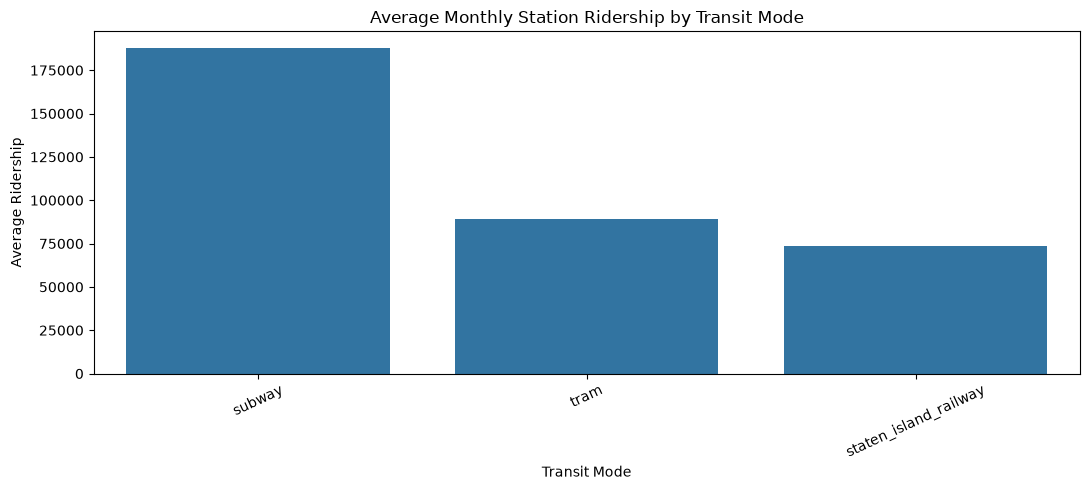

In [7]:
mode_statistics = get_transit_mode_statistics(connection)
display(mode_statistics)

fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    data=mode_statistics,
    x="transit_mode",
    y="average_ridership",
    ax=ax,
)

ax.set_title("Average Monthly Station Ridership by Transit Mode")
ax.set_xlabel("Transit Mode")
ax.set_ylabel("Average Ridership")
ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

### Interpretation

Transit-mode comparisons should account for differences in network coverage, station counts and observation frequency. Average ridership alone does not represent total network demand or service efficiency.


## 7. Independent-sample comparison: Wednesday vs Saturday

The production Mann?Whitney U function compares the sampled Wednesday and Saturday daily ridership observations as independent samples.

**Null hypothesis (H?):** The two samples have the same underlying distribution.

**Alternative hypothesis (H?):** The distributions differ.

The test is supplementary to the paired analysis below. Its independence assumption does not account for the fact that observations were deliberately selected within the same months.


In [8]:
independent_result = compare_weekday_weekend_ridership(connection)

independent_summary = pd.DataFrame([independent_result])
display(independent_summary)

print("Mann?Whitney U statistic:", independent_result["mann_whitney_u_statistic"])
print("P-value:", independent_result["p_value"])
print("Significance level:", independent_result["significance_level"])
print("Statistically significant:", independent_result["statistically_significant"])

,wednesday_sample_size,saturday_sample_size,wednesday_mean_ridership,saturday_mean_ridership,wednesday_median_ridership,saturday_median_ridership,mann_whitney_u_statistic,p_value,significance_level,statistically_significant
0,60,60,3208250.73,2003929.13,3549315.5,2207840.5,2910.0,5.767449e-09,0.05,True


Mann?Whitney U statistic: 2910.0
P-value: 5.767448759981875e-09
Significance level: 0.05
Statistically significant: True


## 8. Paired comparison: matched monthly observations

The production paired function matches sampled Wednesday and Saturday daily ridership within each month.

**Null hypothesis (H?):** The median paired difference is zero.

**Alternative hypothesis (H?):** The paired difference is not zero.

The Wilcoxon signed-rank test evaluates the paired differences. The production implementation additionally estimates the mean paired difference, a 95% t-based confidence interval and rank-biserial correlation.


In [9]:
paired_result = compare_paired_weekday_weekend_ridership(connection)

paired_summary = pd.DataFrame([paired_result])
display(paired_summary)

print("Matched months:", paired_result["paired_months"])
print("Wednesday mean:", paired_result["wednesday_mean_ridership"])
print("Saturday mean:", paired_result["saturday_mean_ridership"])
print("Mean paired difference:", paired_result["mean_paired_difference"])
print(
    "95% confidence interval:",
    (
        paired_result["mean_difference_ci_95_lower"],
        paired_result["mean_difference_ci_95_upper"],
    ),
)
print("Wilcoxon statistic:", paired_result["wilcoxon_statistic"])
print("P-value:", paired_result["p_value"])
print("Rank-biserial correlation:", paired_result["rank_biserial_correlation"])
print("Statistically significant:", paired_result["statistically_significant"])

,paired_months,wednesday_mean_ridership,saturday_mean_ridership,mean_paired_difference,median_paired_difference,mean_difference_ci_95_lower,mean_difference_ci_95_upper,wilcoxon_statistic,p_value,rank_biserial_correlation,statistically_significant
0,60,3208250.73,2003929.13,1204321.6,1220108.5,1059597.4,1349045.8,0.0,1.629556e-11,1.0,True


Matched months: 60
Wednesday mean: 3208250.73
Saturday mean: 2003929.13
Mean paired difference: 1204321.6
95% confidence interval: (1059597.4, 1349045.8)
Wilcoxon statistic: 0.0
P-value: 1.6295557943119345e-11
Rank-biserial correlation: 1.0
Statistically significant: True


## 9. Visualize paired monthly differences

Reconstruct the monthly matched observations for transparent inspection of the paired differences. The statistical test itself remains the production implementation.


In [10]:
paired_monthly = connection.execute(
    """
    WITH daily_totals AS (
        SELECT
            DATE_TRUNC(
                'month', CAST(transit_timestamp AS DATE)
            ) AS sample_month,
            EXTRACT(DOW FROM transit_timestamp)::INTEGER AS day_of_week,
            CAST(transit_timestamp AS DATE) AS sample_date,
            SUM(ridership) AS daily_ridership
        FROM hourly
        WHERE EXTRACT(DOW FROM transit_timestamp)::INTEGER IN (3, 6)
        GROUP BY sample_month, day_of_week, sample_date
    )
    SELECT
        sample_month,
        MAX(CASE WHEN day_of_week = 3
            THEN daily_ridership END) AS wednesday_ridership,
        MAX(CASE WHEN day_of_week = 6
            THEN daily_ridership END) AS saturday_ridership
    FROM daily_totals
    GROUP BY sample_month
    HAVING COUNT(DISTINCT day_of_week) = 2
    ORDER BY sample_month
    """
).df()

paired_monthly["difference"] = (
    paired_monthly["wednesday_ridership"] - paired_monthly["saturday_ridership"]
)

display(paired_monthly.head())
print("Matched observations:", len(paired_monthly))

,sample_month,wednesday_ridership,saturday_ridership,difference
0,2020-01-01,5532410.0,2998682.0,2533728.0
1,2020-02-01,5592887.0,2771985.0,2820902.0
2,2020-03-01,4730600.0,1674663.0,3055937.0
3,2020-04-01,432355.0,264077.0,168278.0
4,2020-05-01,575445.0,365839.0,209606.0


Matched observations: 60


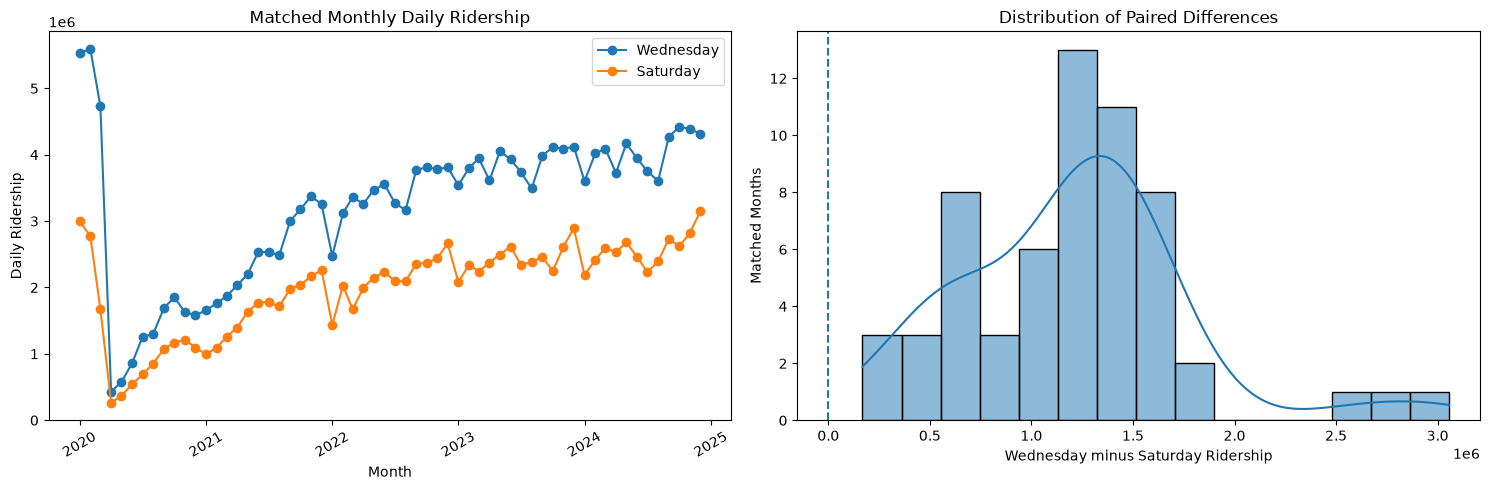

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(
    paired_monthly["sample_month"],
    paired_monthly["wednesday_ridership"],
    marker="o",
    label="Wednesday",
)
axes[0].plot(
    paired_monthly["sample_month"],
    paired_monthly["saturday_ridership"],
    marker="o",
    label="Saturday",
)
axes[0].set_title("Matched Monthly Daily Ridership")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Daily Ridership")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=30)

sns.histplot(
    paired_monthly["difference"],
    bins=15,
    kde=True,
    ax=axes[1],
)
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Distribution of Paired Differences")
axes[1].set_xlabel("Wednesday minus Saturday Ridership")
axes[1].set_ylabel("Matched Months")

plt.tight_layout()
plt.show()

## 10. Statistical interpretation

### Interpreting the p-value

A p-value below 0.05 indicates that the observed result would be relatively unlikely under the corresponding null hypothesis and test assumptions.

It does not measure the probability that the null hypothesis is true, nor does it quantify practical importance.

### Interpreting the confidence interval

The 95% confidence interval is calculated for the mean paired difference using the t distribution. It describes uncertainty around the estimated mean difference under the assumptions of that interval procedure.

### Interpreting rank-biserial correlation

Rank-biserial correlation summarizes the direction and magnitude of the paired rank differences. Positive values indicate that Wednesday values tend to exceed Saturday values; negative values indicate the reverse.

### Comparing the two tests

- Mann?Whitney U compares the two samples without matching individual observations.
- Wilcoxon signed-rank uses the within-month paired differences.
- Because the sampling design selects one Wednesday and one Saturday in each month, the paired analysis aligns more closely with the sampling structure.
- The tests answer related but not identical statistical questions.


In [12]:
alpha = 0.05

print("INDEPENDENT-SAMPLE RESULT")
print("P-value:", independent_result["p_value"])
print("Reject H0:", independent_result["p_value"] < alpha)

print("\nPAIRED-SAMPLE RESULT")
print("P-value:", paired_result["p_value"])
print("Reject H0:", paired_result["p_value"] < alpha)

print("\nEFFECT SIZE")
print("Rank-biserial correlation:", paired_result["rank_biserial_correlation"])

print("\n95% CI FOR MEAN PAIRED DIFFERENCE")
print(
    paired_result["mean_difference_ci_95_lower"],
    "to",
    paired_result["mean_difference_ci_95_upper"],
)

INDEPENDENT-SAMPLE RESULT
P-value: 5.767448759981875e-09
Reject H0: True

PAIRED-SAMPLE RESULT
P-value: 1.6295557943119345e-11
Reject H0: True

EFFECT SIZE
Rank-biserial correlation: 1.0

95% CI FOR MEAN PAIRED DIFFERENCE
1059597.4 to 1349045.8


## 11. Limitations and analytical safeguards

1. **Sampled hourly coverage:** The hourly dataset contains 120 selected dates, not every day from 2020 through 2024.
2. **Matched sample size:** The paired analysis uses months containing both a sampled Wednesday and Saturday.
3. **Temporal dependence:** Monthly observations may not be fully independent across time.
4. **Distributional assumptions:** Wilcoxon signed-rank inference and the t-based confidence interval rely on assumptions about the paired-difference structure; the interval is not a nonparametric confidence interval.
5. **Unequal station demand:** Borough and transit-mode means can be influenced by network size and station characteristics.
6. **Multiple comparisons:** No multiple-testing adjustment is applied to the descriptive group comparisons.
7. **No causal inference:** Observed differences do not demonstrate that day of week alone causes ridership changes.
8. **No passenger-level inference:** Aggregated ridership cannot establish individual travel behavior.

The analytical conclusions should be interpreted within these boundaries.


## 12. Reproducibility checks and cleanup

Confirm that the paired sample reconstructed for visualization agrees with the production function's matched-month count.


In [13]:
assert len(paired_monthly) == paired_result["paired_months"]

assert paired_monthly["difference"].notna().all()
assert len(distribution) == 1
assert not borough_statistics.empty
assert not mode_statistics.empty

print("Paired observation count: PASS")
print("Paired difference completeness: PASS")
print("Distribution summary: PASS")
print("Borough statistics: PASS")
print("Transit-mode statistics: PASS")

connection.close()
print("\nDuckDB connection closed.")

Paired observation count: PASS
Paired difference completeness: PASS
Distribution summary: PASS
Borough statistics: PASS
Transit-mode statistics: PASS

DuckDB connection closed.


## 13. Key takeaways

Complete this section after reviewing the executed outputs.

- **Distribution:** Describe the central tendency, spread and skewness of monthly station-level ridership.
- **Boroughs:** Identify meaningful differences in average and median station-level ridership, considering station counts.
- **Transit modes:** Summarize observed differences without equating averages with total demand.
- **Weekday comparison:** Report the paired-month sample size, mean difference, 95% confidence interval, Wilcoxon p-value and rank-biserial correlation.
- **Statistical caution:** Distinguish statistical significance from practical importance and avoid causal claims.

---

**ChronoTunnel | Turning Transit Data into Smarter Mobility Decisions**
